# 02 · Scores, SDEs, ODEs and density evolution

Connect trajectories to the equations that move probability mass. Compare exact fields before attributing differences to learned models.

**Prerequisites:** 00–01; gradients, divergence and basic stochastic increments.

**By the end:** Check analytic scores; derive VP/VE/sub-VP coefficients; explain reverse-time signs; verify a Fokker–Planck/continuity identity numerically.

Run from top to bottom. Default experiments use CPU, fixed seeds and no downloads. Small trained models illustrate learning; analytic oracles isolate mathematical and solver effects. Neither is an image-quality benchmark.

[Course index](README.md) · [Notation](../docs/23_notation_and_code.md) · [Implementation scope](../docs/15_coverage_and_scope.md)

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image, display

project = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "diffusion_lab").is_dir())
if str(project) not in sys.path:
    sys.path.insert(0, str(project))
torch.set_num_threads(2)
torch.manual_seed(7)
np.random.seed(7)
plt.rcParams.update(
    {
        "figure.figsize": (10, 3.6),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.dpi": 100,
    }
)
ENABLE_WIDGETS = False  # Set True in Jupyter; static figures work on GitHub.
print(f"PyTorch {torch.__version__}; CPU lesson; seed=7; no automatic downloads.")


def scatter(ax, samples, title, labels=None, limits=(-4.5, 4.5)):
    points = samples.detach().cpu().numpy()
    colors = labels.detach().cpu().numpy() if labels is not None else "steelblue"
    ax.scatter(
        points[:, 0],
        points[:, 1],
        c=colors,
        cmap="tab10" if labels is not None else None,
        s=5,
        alpha=0.55,
        linewidths=0,
    )
    ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$", aspect="equal", xlim=limits, ylim=limits)


def saved_gallery(relative, caption):
    path = project / relative
    if not path.is_file():
        raise FileNotFoundError(f"Missing curated course evidence: {relative}")
    print(caption)
    display(Image(filename=str(path)))


def animate_particles(history, name, title, labels=None, limits=(-4.5, 4.5)):
    from matplotlib.animation import FuncAnimation, PillowWriter

    points = history.detach().cpu().numpy()
    indices = np.linspace(0, len(points) - 1, min(32, len(points))).astype(int)
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    colors = labels.detach().cpu().numpy() if labels is not None else "steelblue"
    dots = ax.scatter(
        *points[0].T,
        c=colors,
        cmap="tab10" if labels is not None else None,
        s=9,
        alpha=0.65,
        linewidths=0,
    )
    ax.set(xlim=limits, ylim=limits, aspect="equal", xlabel="$x_1$", ylabel="$x_2$")

    def update(frame):
        dots.set_offsets(points[indices[frame]])
        ax.set_title(f"{title}: frame {frame + 1}/{len(indices)}")
        return (dots,)

    animation = FuncAnimation(fig, update, frames=len(indices), interval=100)
    folder = project / "assets/teaching/notebooks"
    folder.mkdir(parents=True, exist_ok=True)
    target = folder / f"{name}.gif"
    animation.save(target, writer=PillowWriter(fps=10), dpi=75)
    plt.close(fig)
    display(Image(filename=str(target)))

PyTorch 2.7.1+cu128; CPU lesson; seed=7; no automatic downloads.


## 1. A score points toward increasing log density

For an isotropic Gaussian, $s(x)=-(x-\mu)/v$. A mixture score is a
**posterior-responsibility-weighted** average of component scores, not their
unweighted sum. It need not point toward the nearest mean everywhere.
We compare `GaussianMixture.score` with differentiation of `log_prob`.
**Code:** [data.py](../diffusion_lab/data.py).

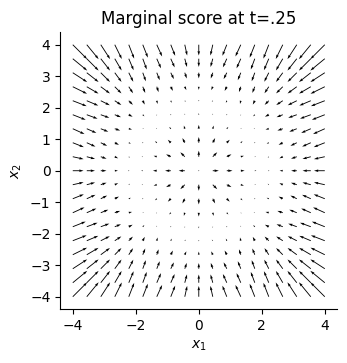

In [2]:
from diffusion_lab.data import GaussianMixture
from diffusion_lab.paths import GaussianPath, expand
from diffusion_lab.solvers import integrate

mixture, path = GaussianMixture(), GaussianPath("vp_linear")
grid = torch.linspace(-4, 4, 19)
yy, xx = torch.meshgrid(grid, grid, indexing="ij")
x = torch.stack([xx.flatten(), yy.flatten()], dim=1).requires_grad_(True)
t = torch.full((len(x),), 0.25)
a, s = path.coefficients(t)
automatic = torch.autograd.grad(mixture.log_prob(x, a, s).sum(), x)[0]
analytic = mixture.score(x, a, s)
torch.testing.assert_close(analytic, automatic, atol=2e-5, rtol=2e-5)
fig, ax = plt.subplots()
ax.quiver(x[:, 0].detach(), x[:, 1].detach(), analytic[:, 0].detach(), analytic[:, 1].detach())
ax.set(title="Marginal score at t=.25", aspect="equal", xlabel="$x_1$", ylabel="$x_2$")
plt.show()

## 2. From corruption coefficients to an SDE

For $dX_t=F(t)X_tdt+g(t)dW_t$, Gaussian corruption requires
$$F=\alpha'/\alpha,\qquad g^2=(\sigma^2)'-2F\sigma^2.$$
This follows from mean and variance evolution. With $B=\int\beta$:

| Family | $f(x,t)$ | $g(t)^2$ | Noise standard deviation |
|---|---|---|---|
| VP | $-\beta x/2$ | $\beta$ | $\sqrt{1-e^{-B}}$ |
| sub-VP | $-\beta x/2$ | $\beta(1-e^{-2B})$ | $1-e^{-B}$ |
| VE | $0$ | $(\sigma^2)'$ | Exponential sigma in this implementation |

All examples use state-independent diffusion (additive noise); general
state-dependent diffusion needs additional terms. **Code:** `GaussianPath.sde` in [paths.py](../diffusion_lab/paths.py).

In [3]:
for kind in ["vp_linear", "vp_cosine", "sub_vp", "ve", "vp_logsnr", "vp_exponential"]:
    candidate = GaussianPath(kind)
    time = torch.linspace(0.1, 0.8, 40, dtype=torch.float64).requires_grad_(True)
    a, s = candidate.coefficients(time)
    da = (
        torch.autograd.grad(a.sum(), time, retain_graph=True)[0]
        if a.requires_grad
        else torch.zeros_like(a)
    )
    ds2 = torch.autograd.grad(s.square().sum(), time)[0]
    F = da / a
    f, g = candidate.sde(torch.ones(len(time), 2, dtype=time.dtype), time)
    torch.testing.assert_close(f[:, 0], F, atol=1e-8, rtol=1e-8)
    torch.testing.assert_close(g.square(), ds2 - 2 * F * s.square(), atol=1e-8, rtol=1e-8)
    print(kind, "mean/variance SDE identity passed")

vp_linear mean/variance SDE identity passed
vp_cosine mean/variance SDE identity passed
sub_vp mean/variance SDE identity passed
ve mean/variance SDE identity passed
vp_logsnr mean/variance SDE identity passed
vp_exponential mean/variance SDE identity passed


## 3. Reverse clock: signs matter

Forward $t$ runs data → noise. Using the **same decreasing clock** for generation:
$$dX_t=[f-g^2s_t]dt+g\,d\overline W_t,\qquad dt<0,$$
$$\frac{dX_t}{dt}=f-\tfrac12g^2s_t \quad\text{(probability-flow ODE)}.$$
Brownian increment variance is $|dt|$. Alternatively use $r=1-t$ increasing:
reverse drift becomes $-f+g^2s_t$, ODE drift $-f+g^2s_t/2$.
Do not apply a reversed sign **and** a decreasing grid.

Exact score, matching initial marginal, regularity and exact integration give
the same time marginals for SDE and ODE. Their individual trajectories differ.
We initialize from the actual finite-time marginal, avoiding an approximate-prior confound.
**Code:** [solvers.py](../diffusion_lab/solvers.py), [sampling.py](../diffusion_lab/sampling.py).

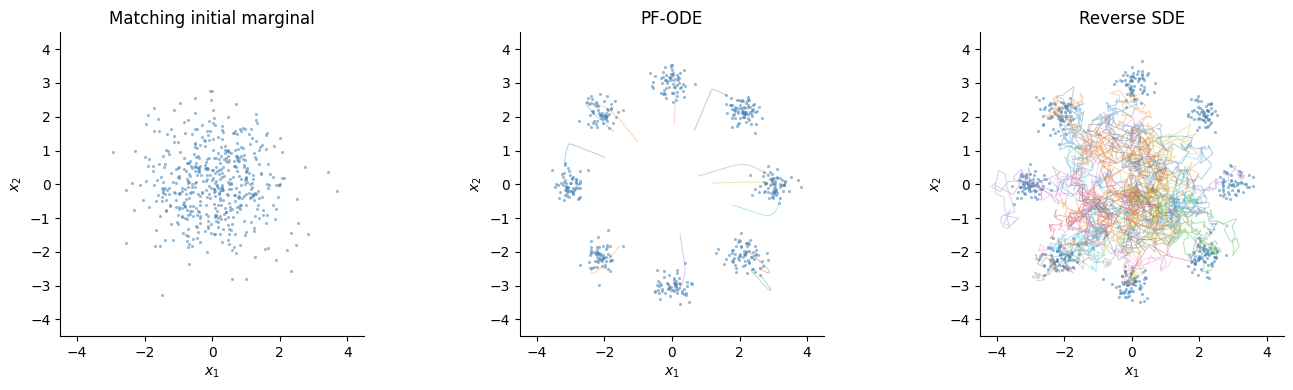

Finite endpoint t=.005 and solver error remain; trajectories need not coincide.


In [4]:
g = torch.Generator().manual_seed(31)
clean, labels = mixture.sample(512, g)
a, s = path.coefficients(torch.full((len(clean),), 0.99))
initial = expand(a, clean) * clean + expand(s, clean) * torch.randn(clean.shape, generator=g)


def score(x, t):
    return mixture.score(x, *path.coefficients(t))


def ode_field(x, t):
    f, g = path.sde(x, t)
    return f - 0.5 * expand(g.square(), x) * score(x, t)


def reverse_drift(x, t):
    f, g = path.sde(x, t)
    return f - expand(g.square(), x) * score(x, t)


def diffusion(t):
    return path.sde(torch.zeros(len(t), 2), t)[1]


times = torch.linspace(0.99, 0.005, 301)
ode, ode_history = integrate(ode_field, initial, times, "heun")
sde, sde_history = integrate(
    reverse_drift, initial, times, "euler_maruyama", diffusion, torch.Generator().manual_seed(32)
)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
scatter(axes[0], initial, "Matching initial marginal")
for ax, samples, history, title in zip(
    axes[1:], [ode, sde], [ode_history, sde_history], ["PF-ODE", "Reverse SDE"], strict=True
):
    ax.plot(history[:, :12, 0], history[:, :12, 1], alpha=0.35, linewidth=0.7)
    scatter(ax, samples, title)
plt.tight_layout()
plt.show()
print("Finite endpoint t=.005 and solver error remain; trajectories need not coincide.")

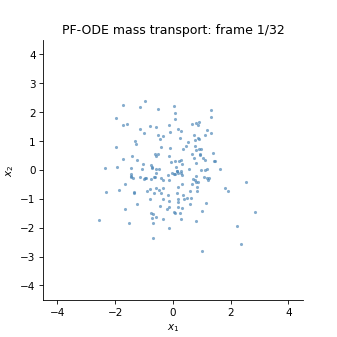

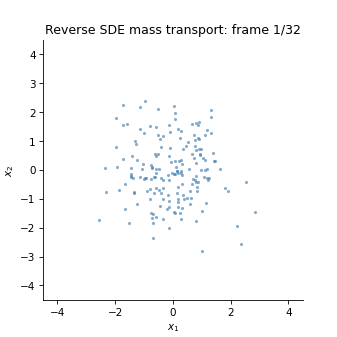

In [5]:
animate_particles(ode_history[:, :180], "02_probability_flow", "PF-ODE mass transport")
animate_particles(sde_history[:, :180], "02_reverse_sde", "Reverse SDE mass transport")

## 4. Fokker–Planck becomes continuity

For state-independent $g(t)$,
$$\partial_t p=-\nabla\cdot(fp)+\tfrac12g^2\Delta p.$$
Since $p s_t=\nabla p$, define $u=f-g^2s_t/2$ and obtain
$$\partial_t p+\nabla\cdot(up)=0.$$
One equation evolves density under an SDE; the other under a deterministic
velocity. Equal PDEs explain equal marginals, not equal paths.
The following uses **autograd in double precision** to check a local residual
of the analytic GMM density. This is a derivative consistency check, not a proof
for all fields. **Code connection:** `field_and_divergence` in [likelihood.py](../diffusion_lab/likelihood.py).

In [6]:
x = torch.randn(48, 2, dtype=torch.float64, requires_grad=True)
t = torch.full((len(x),), 0.35, dtype=torch.float64, requires_grad=True)
a, s = path.coefficients(t)
p = mixture.log_prob(x, a, s).exp()
dpdt = torch.autograd.grad(p.sum(), t, create_graph=True)[0]
gradp = torch.autograd.grad(p.sum(), x, create_graph=True)[0]
f, g = path.sde(x, t)
u = f - 0.5 * expand(g.square(), x) * mixture.score(x, a, s)


def divergence(vector):
    return sum(
        torch.autograd.grad(vector[:, j].sum(), x, create_graph=True, retain_graph=True)[0][:, j]
        for j in range(2)
    )


laplacian = divergence(gradp)
fp_residual = dpdt + divergence(f * p[:, None]) - 0.5 * g.square() * laplacian
continuity_residual = dpdt + divergence(u * p[:, None])
print(
    "Max Fokker–Planck / continuity residual:",
    fp_residual.abs().max().item(),
    continuity_residual.abs().max().item(),
)
assert fp_residual.abs().max() < 1e-8
assert continuity_residual.abs().max() < 1e-8

Max Fokker–Planck / continuity residual: 1.6653345369377348e-16 2.220446049250313e-16


## Exercises and worked answers

1. Write the reverse-SDE drift with an increasing generation clock.
2. Why does PF-ODE use half the score coefficient?
3. Compare 50 and 600 steps; use [sliced Wasserstein](../diffusion_lab/metrics.py) against independently drawn endpoint reference samples. Repeat SDE noise seeds.

<details><summary>Worked answers</summary>

1. $-f(x,1-r)+g(1-r)^2s_{1-r}(x)$; Brownian coefficient remains $g(1-r)$.
2. The other half is represented by the SDE's diffusion/Laplacian term.
3. Empirical distribution distance mixes numerical and finite-sample error. A shared initial sample makes comparisons more controlled but does not eliminate Monte Carlo error.

</details>

**Animations:** [ODE](../assets/teaching/notebooks/02_probability_flow.gif), [SDE](../assets/teaching/notebooks/02_reverse_sde.gif).
**Continue:** [Flow matching](03_flow_matching_and_solvers.ipynb).
**Source:** [Song et al.](https://arxiv.org/abs/2011.13456).